Implementation of Metropolis adjusted IPLA (in a MALA form) for Bayesian Logistic regression

In [12]:
from pathlib import Path
import numpy as np 
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

In [13]:
data = np.load("../data/synthetic_logistic_regression.npz")
sigma = 0.05

v = jnp.asarray(data["v"])
y = jnp.asarray(data["y"])
x_true = jnp.asarray(data["x_true"])

In [23]:
def sumU(theta, X, v=v, y=y, sigma=sigma):
    log_lik = jnp.sum(y * jax.nn.log_sigmoid(X @ v.T) 
                         + (1-y) * jax.nn.log_sigmoid(-X @ v.T))
    log_prior = - 0.5 / sigma**2 * (jnp.log(2 * jnp.pi * sigma**2)) 
    + jnp.sum((X-theta)**2) /sigma**2

    return - jnp.sum(log_lik + log_prior)

Ugrad_th = jax.grad(sumU, argnums=0)
Ugrad_X = jax.grad(sumU, argnums=1)

def log_phi(theta_prop, theta, X, gamma):
    N = X.shape[0]
    mean = theta - gamma / N * Ugrad_th(theta, X)
    var = 2*gamma/N
    phi = - theta.shape[0] / 2 * jnp.log(2*jnp.pi*sigma**2)
    - 0.5 * jnp.sum((theta_prop - mean)**2) / var

    return phi

def log_psi_total(X_prop, theta, X, gamma):
    N, d_x = X.shape

    means = X - gamma * Ugrad_X(theta, X)
    var = 2 * gamma

    return (
        -0.5 * jnp.sum((X_prop - means)**2) / var
        -0.5 * N * d_x * jnp.log(2 * jnp.pi * var)
    )

def log_proposal(X_prop, theta_prop, X, theta, gamma):
    return (
        log_phi(theta_prop, theta, X, gamma) 
        + log_psi_total(X_prop, theta, X, gamma)
    )

def log_acc(X_prop, theta_prop, X, theta, gamma):
    log_target = -sumU(theta, X)
    log_target_prop = -sumU(theta_prop, X_prop)

    log_q_fwd = log_proposal(X_prop, theta_prop, X, theta, gamma)
    log_q_rvs = log_proposal(X, theta, X_prop, theta_prop, gamma)

    return (
        log_target_prop - log_target
        + log_q_rvs - log_q_fwd
    )

In [24]:
def maipla(N, gamma, n_iter, theta0, X0, key):
    theta = theta0
    X = X0
    theta_history = [theta]
    x_history = [X]

    for _ in range(n_iter):
        
        key, key_theta, key_particles, key_unif = jax.random.split(key, 4)
        xi_theta = jax.random.normal(key_theta, shape=theta.shape)
        xi_x = jax.random.normal(key_particles, shape=X.shape)

        theta_prop = theta - gamma / N * Ugrad_th(theta, X) + jnp.sqrt(2 * gamma / N) * xi_theta
        X_prop = X - gamma * Ugrad_X(theta, X) + jnp.sqrt(2 * gamma) * xi_x

        u = jax.random.uniform(key_unif)
        log_acceptance = log_acc(X_prop, theta_prop, X, theta, gamma)

        if jnp.log(u) < log_acceptance:
            theta = theta_prop
            X = X_prop

        theta_history.append(theta)
        x_history.append(X)

    return theta, jnp.stack(theta_history), jnp.stack(x_history)

In [25]:
# Run the experiment
N = 100
gamma = 0.001
n_iter = 2000

theta0 = jnp.zeros(3)

key = jax.random.key(108)
key, key_x, key_maipla = jax.random.split(key, 3)

x0 = jax.random.normal(key_x, shape=(N, 3))

theta_final, theta_hist, x_hist = maipla(
    N, gamma, n_iter, theta0, x0, key_maipla
)



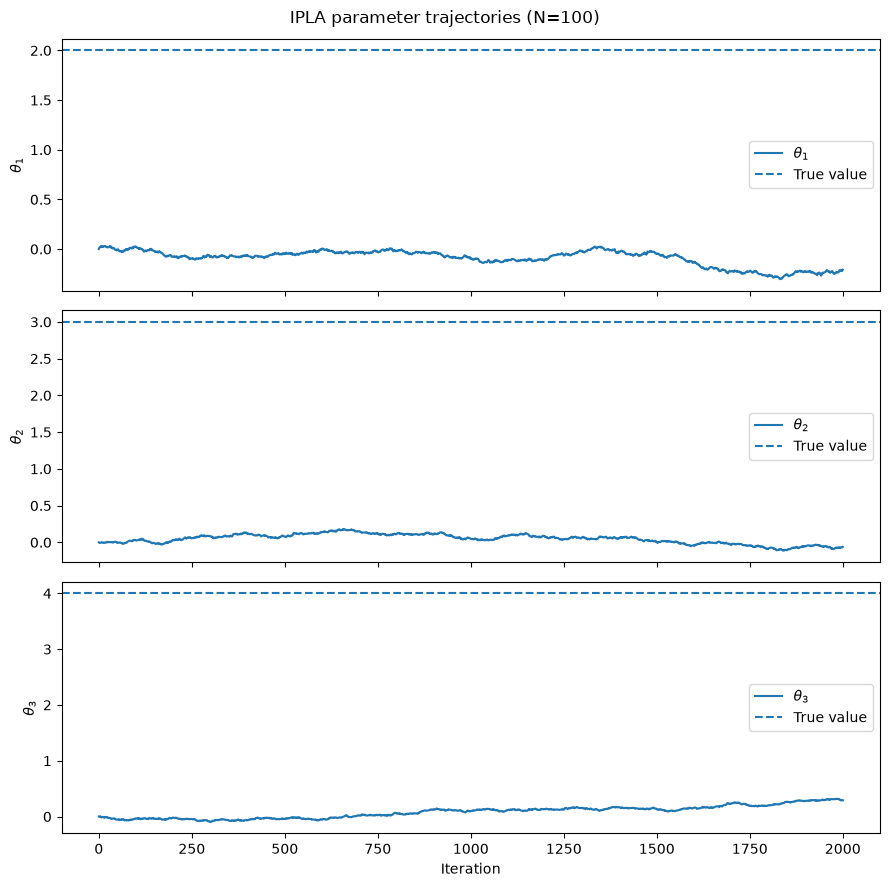

In [26]:
theta_history = np.asarray(theta_hist)
theta_true = np.array([2.0, 3.0, 4.0])

fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(theta_history[:, i], label=f"$\\theta_{i+1}$")
    ax.axhline(theta_true[i], linestyle="--", label="True value")
    ax.set_ylabel(f"$\\theta_{i+1}$")
    ax.legend()

axes[-1].set_xlabel("Iteration")
fig.suptitle(f"IPLA parameter trajectories (N={N})")
plt.tight_layout()
plt.show()